<a href="https://colab.research.google.com/github/AKookani/BrickwallCliffordCircuit/blob/main/Toy%20Stabilizer%20MIPT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install qiskit ipywidgets
!pip install pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 63.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 91.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 108.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 88.6 MB/s eta 0:00:00


**Stabilizer States' Entanglment Entropy**
$$S(A) = |A| - \operatorname{rank}(\mathcal{G}_A)$$

where:

  * $|A|$ is the number of qubits in subsystem $A$,
  * $\mathcal{G}_A$ is the matrix of independent stabilizers supported entirely on $A$,
  * $\operatorname{rank}(\mathcal{G}_A)$ is the number of independent generators of $A$

In [ ]:
def stabilizer_entropy(state, A):
    """S(A) = |A| - rank(G_A), rank(G_A) counted from the definition."""
    n = state.clifford.num_qubits
    gens = [Pauli(lab.lstrip('+-')) for lab in state.clifford.to_labels(mode="S")]
    print(gens)
    outside = [q for q in range(n) if q not in A]

    count = 0                                   # number of group elements supported on A
    for bits in product([0, 1], repeat=n):      # every element of the stabilizer group
        g = Pauli('I' * n)
        for b, s in zip(bits, gens):
            if b:
                g = g.compose(s)
        support = g.x | g.z                     # qubits where g is not identity
        if not support[outside].any():          # identity on the complement of A
            count += 1

    rank = count.bit_length() - 1               # count = 2^rank
    return len(A) - rank

In [ ]:
import numpy as np
from itertools import product
from qiskit.quantum_info import Pauli

def stabilizer_entropy(state, A, verbose=True):
    """S(A) = |A| - rank(G_A); rank(G_A) = number of independent generators on A."""
    n = state.clifford.num_qubits
    gens = [Pauli(lab) for lab in state.clifford.to_labels(mode="S")]
    outside = np.array([q for q in range(n) if q not in A], dtype=int)
    key = lambda p: (tuple(p.x), tuple(p.z))      # sign-independent identity of a Pauli

    # 1. All stabilizer-group elements that act as identity outside A
    supported = []
    for bits in product([0, 1], repeat=n):
        g = Pauli('I' * n)
        for b, s in zip(bits, gens):
            if b:
                g = g.compose(s)
        if not (g.x | g.z)[outside].any():
            supported.append(g)

    # 2. Pick independent generators: an element is a new generator only if
    #    it is not already a product of the generators chosen so far.
    identity = Pauli('I' * n)
    span = {key(identity): identity}              # group generated so far
    indep = []
    for g in supported:
        if key(g) not in span:
            indep.append(g)
            span.update({key(h.compose(g)): h.compose(g) for h in list(span.values())})

    rank = len(indep)
    S = len(A) - rank

    if verbose:
        print(f"A = {list(A)}, |A| = {len(A)}")
        print(f"Stabilizer group generators: {[str(g) for g in gens]}")
        print(f"Independent generators supported on A (rank = {rank}):")
        for g in indep:
            print(f"   {g}")
        if not indep:
            print("   (none)")
        print(f"S(A) = {len(A)} - {rank} = {S}\n")

    return S

t=0
A = [0], |A| = 1
Stabilizer group generators: ['-XX', '-ZZ']
Independent generators supported on A (rank = 0):
   (none)
S(A) = 1 - 0 = 1

entorpy:1
t=1
measured qubit 1 -> 1
A = [0], |A| = 1
Stabilizer group generators: ['-ZX', '-ZI']
Independent generators supported on A (rank = 1):
   IX
S(A) = 1 - 1 = 0

entorpy:0
t=2
A = [0], |A| = 1
Stabilizer group generators: ['-ZX', '-ZI']
Independent generators supported on A (rank = 1):
   IX
S(A) = 1 - 1 = 0

entorpy:0
t=3
A = [0], |A| = 1
Stabilizer group generators: ['-XX', '-XI']
Independent generators supported on A (rank = 1):
   IX
S(A) = 1 - 1 = 0

entorpy:0
t=4
measured qubit 1 -> 1
A = [0], |A| = 1
Stabilizer group generators: ['-ZX', '-ZI']
Independent generators supported on A (rank = 1):
   IX
S(A) = 1 - 1 = 0

entorpy:0
t=5
A = [0], |A| = 1
Stabilizer group generators: ['-ZX', '-ZI']
Independent generators supported on A (rank = 1):
   IX
S(A) = 1 - 1 = 0

entorpy:0
t=6
measured qubit 1 -> 0
A = [0], |A| = 1
Stabilizer grou

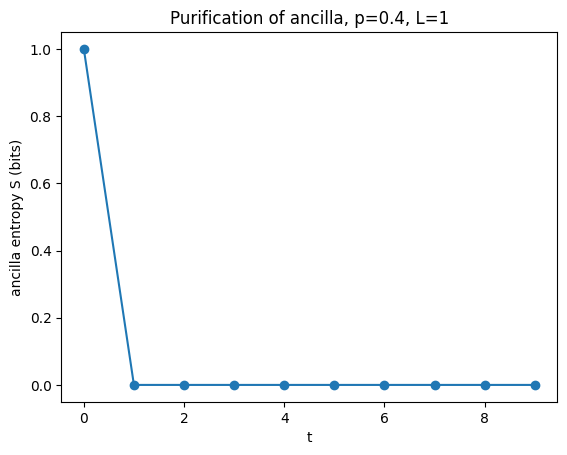

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import (StabilizerState, Clifford, Statevector,
                                 random_clifford)

size, T, p_measure = 1, 10, 0.4
rng = np.random.default_rng()

# Qubit 0 = ancilla, qubits 1..size = system
init = QuantumCircuit(size + 1)
init.h(0)
init.cx(0, 1 + size // 2)          # Bell pair: ancilla <-> middle system qubit
state = StabilizerState(init)

system = list(range(1, size + 1))
S_history = []

for t in range(T):
    print(f"t={t}")
    # 1. Unitary layer: random Clifford on the system
    state = state.evolve(random_clifford(size, seed=rng), qargs=system)

    # 2. Measurement + reset on a random system qubit, with probability p
    if rng.random() < p_measure:
        q = int(rng.choice(system))
        outcome, state = state.measure([q])
        print(f"measured qubit {q} -> {outcome}")

    # 3. Entanglement entropy of the ancilla (bits)
    cliff = state.clifford.to_circuit()
    S_history.append(stabilizer_entropy(state, A=[0]))
    print(f"entorpy:{S_history[t]}")

plt.plot(S_history, 'o-')
plt.xlabel('t'); plt.ylabel('ancilla entropy S (bits)')
plt.title(f'Purification of ancilla, p={p_measure}, L={size}')
plt.show()

Evolution & meansurement in stabilizers